## Penalized Regression: Ridge and LASSO

So far we have approached feature selection---that is, selection of which ${\bf X}$ variables to based our predictions on---by considering several subsets of features and comparing scores. But what if we want to consider *all* of the features? We don't necessarily want to select all the features to include in our model, because we run the risk of overfitting to the training data. But maybe we want to *consider* every feature for selection rather than just a few subsets. Penalized regression is one way of performing de facto feature selection: throw all the available features into the model and let the model fitting sort out which to include.

In [2]:
import pandas as pd
import numpy as np
from sklearn.pipeline import Pipeline
from sklearn.compose import make_column_selector, ColumnTransformer
from sklearn.preprocessing import StandardScaler, OneHotEncoder, PolynomialFeatures
from sklearn.linear_model import LinearRegression, Ridge, Lasso, ElasticNet
from sklearn.model_selection import cross_val_score
from sklearn.metrics import r2_score

We'll use the Ames housing data. We'll do a little cleaning first to:

- Drop a few columns that have mostly missing values
- Drop a few rows with missing values
- Drop the ID columns (row order and PID)

In [7]:
ames = pd.read_csv("AmesHousing.txt", sep="\t")

# Get rid of columns with mostly NaN values
good_cols = ames.isna().sum() < 100
ames = ames.loc[:,good_cols]

# Drop other NAs
ames = ames.dropna()

# drop ID columns and put target in y
X = ames.drop(["SalePrice", "Order", "PID"], axis = 1)
y = ames["SalePrice"]

X

,MS SubClass,MS Zoning,Lot Area,Street,Lot Shape,Land Contour,Utilities,Lot Config,Land Slope,Neighborhood,...,Open Porch SF,Enclosed Porch,3Ssn Porch,Screen Porch,Pool Area,Misc Val,Mo Sold,Yr Sold,Sale Type,Sale Condition
0,20,RL,31770,Pave,IR1,Lvl,AllPub,Corner,Gtl,NAmes,...,62,0,0,0,0,0,5,2010,WD,Normal
1,20,RH,11622,Pave,Reg,Lvl,AllPub,Inside,Gtl,NAmes,...,0,0,0,120,0,0,6,2010,WD,Normal
2,20,RL,14267,Pave,IR1,Lvl,AllPub,Corner,Gtl,NAmes,...,36,0,0,0,0,12500,6,2010,WD,Normal
3,20,RL,11160,Pave,Reg,Lvl,AllPub,Corner,Gtl,NAmes,...,0,0,0,0,0,0,4,2010,WD,Normal
4,60,RL,13830,Pave,IR1,Lvl,AllPub,Inside,Gtl,Gilbert,...,34,0,0,0,0,0,3,2010,WD,Normal
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
2925,80,RL,7937,Pave,IR1,Lvl,AllPub,CulDSac,Gtl,Mitchel,...,0,0,0,0,0,0,3,2006,WD,Normal
2926,20,RL,8885,Pave,IR1,Low,AllPub,Inside,Mod,Mitchel,...,0,0,0,0,0,0,6,2006,WD,Normal
2927,85,RL,10441,Pave,Reg,Lvl,AllPub,Inside,Gtl,Mitchel,...,32,0,0,0,0,700,7,2006,WD,Normal
2928,20,RL,10010,Pave,Reg,Lvl,AllPub,Inside,Mod,Mitchel,...,38,0,0,0,0,0,4,2006,WD,Normal


In [8]:
y

0       215000
1       105000
2       172000
3       244000
4       189900
         ...  
2925    142500
2926    131000
2927    132000
2928    170000
2929    188000
Name: SalePrice, Length: 2821, dtype: int64

Let's try a linear regression model first. We'll standardize numerical predictors and dummify categorical predictors.

In [9]:
ct = ColumnTransformer(
  [
    ("dummify",
    OneHotEncoder(sparse_output = False, handle_unknown='ignore'),
    make_column_selector(dtype_include=object)),
    ("standardize",
    StandardScaler(),
    make_column_selector(dtype_include=np.number))
  ],
  remainder = "passthrough"
).set_output(transform="pandas")

In [10]:
lr_pipeline = Pipeline(
  [("preprocessing", ct),
  ("linear_regression", LinearRegression())]
)

In [11]:
lr_pipeline.fit(X, y)

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators ` for more details.","[('preprocessing', ...), ('linear_regression', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing `.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('dummify', ...), ('standardize', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='passthrough'``, all remaining columns thatwere not specified in `transformers`, but present in the data passedto `fit` will be automatically passed through. This subset of columnsis concatenated with the output of the transformers. For dataframes,extra columns not seen during `fit` will be excluded from the outputof `transform`.By setting ``remainder`` to be an estimator, the remainingnon-specified columns will use the ``remainder`` estimator. Theestimator must support :term:`fit` and :term:`transform`.Note that using this feature requires that the DataFrame columnsinput at :term:`fit` and :term:`transform` have identical order.",'passthrough'
,"sparse_threshold sparse_threshold: float, default=0.3If the output 

Now let's use cross-validation to evaluate based on $R^2$.

In [12]:
cross_val_score(lr_pipeline, X, y, cv = 10, scoring = 'r2')

array([0.88433686, 0.90316706, 0.87507511, 0.91216037, 0.82269502, 0.73890838,
       0.86879893, 0.63798647, 0.90277443, 0.90350125])

Hmmm... linear regression on all the predictors does not seem as bad as the textbook suggests, though there is considerably variability between the scores based on the different folds.

Let's add second degree polynomial terms for all numerical predictors and see what happens.

In [13]:
numeric_poly = Pipeline([
    ("polynomial_features", PolynomialFeatures(degree=2)),
    ("standardize", StandardScaler())
])

ct_poly = ColumnTransformer(
    [
        ("dummify",
         OneHotEncoder(sparse_output=False, handle_unknown="ignore"),
         make_column_selector(dtype_include=object)),

        ("numeric_poly",
         numeric_poly,
         make_column_selector(dtype_include=np.number))
    ],
    remainder="drop"
).set_output(transform="pandas")

In [14]:
poly_pipeline = Pipeline(
  [("preprocessing", ct_poly),
  ("linear_regression", LinearRegression())]
)

In [15]:
poly_pipeline.fit(X, y)

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators ` for more details.","[('preprocessing', ...), ('linear_regression', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing `.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('dummify', ...), ('numeric_poly', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='passthrough'``, all remaining columns thatwere not specified in `transformers`, but present in the data passedto `fit` will be automatically passed through. This subset of columnsis concatenated with the output of the transformers. For dataframes,extra columns not seen during `fit` will be excluded from the outputof `transform`.By setting ``remainder`` to be an estimator, the remainingnon-specified columns will use the ``remainder`` estimator. Theestimator must support :term:`fit` and :term:`transform`.Note that using this feature requires that the DataFrame columnsinput at :term:`fit` and :term:`transform` have identical order.",'drop'
,"sparse_threshold sparse_threshold: float, default=0.3If the output of the

In [16]:
cross_val_score(poly_pipeline, X, y, cv = 10, scoring = 'r2')

array([  0.88322049,  -0.2351045 ,  -5.18937934,   0.23576715, -25.57250127,
         0.65934136,   0.23955858,  -1.0532801 ,  -3.71975499, -51.70824836])

OK, now that's bad. The moral is that just throwing in all the predictors might fit the training data well but can be pretty terrible when it comes to making predictions for new observations. We want to be more selective without having to laboriously search through all the possible subsets of predictors. With 67 predictors there are $2^{67}\approx 10^{20}$ possible subsets---even before we consider polynomial terms, interactions, transformations, etc---so it would be impossible to fit every possible subset.

Instead, we include all predictors but "penalize" variables that don't contribute much to the model. Before getting to the penalty we'll consider some motivating conceptual questions.

1. Consider a simple linear regression of sale price on a single variable like living area. What is the process by which the coefficient for living area is determined? How does "least squares" work? **DISCUSS**

2. Now consider a multiple of regression on living area and number of bedrooms, without standardizing variables. How does least squares work in this case? **DISCUSS**

3. If you fit the linear model, without standarizing variables, how do you interpret the coefficients for living area and number of bedrooms? What is their rough order of magnitude? Can we determine directly from the coefficients which variable the predicted prices are more sensitive to? **DISCUSS**

4. If you standardize the variables first, how would you interpret the model coefficients? How could you determine, roughly, which variable the predicted prices are more sensitive to? **DISCUSS**

5. If we want to make the predictions *less* sensitive to a particular standardized variable, what in principle should we do to its coefficient? **DISCUSS**

6. If we want to make the predictions *not at all* sensitive to a particular standardized variable, what in principle should we do to its coefficient? **DISCUSS**

7. Why does including a penalty like in ridge regression or LASSO "shrink" coefficients towards 0? **DISCUSS**

8. Why is it important to standarize variables when using a penalty? **DISCUSS**

9. What happens if the penalty parameter $\lambda$ is 0? **DISCUSS**

10. What happens as the penalty parameter $\lambda$ gets larger and larger? **DISCUSS**

11. Why do we not penalize the intercept? **DISCUSS**

12. Assume $\lambda = 1$. Suppose a standardized predictor has a small coefficient, say $\beta = 0.1$. How much does that coefficient add to the LASSO penalty versus the ridge penalty? If the coefficient were reduced from 0.1 to 0, how much would each penalty decrease? Which penalty offers a larger payoff for eliminating a small coefficient entirely? **DISCUSS**

- Ridge regression shrinks all coefficient estimates toward zero but typically keeps every predictor in the model.
- LASSO regression shrinks coefficients and can set some exactly to zero, automatically removing those predictors.
- Choose ridge when predictors are highly correlated and you think many of them contain useful predictive information. Ridge tends to share influence among correlated variables.
- Choose LASSO when you want a simpler, more interpretable model with automatic variable selection.
- With highly correlated predictors, LASSO may keep one and drop the others—sometimes somewhat arbitrarily—while ridge usually retains all of them with smaller coefficients.
- Both methods are useful when there are many predictors or when ordinary least squares may overfit.

**Note that in scikit-learn the penalty parameter $\lambda$ is called `alpha`.**

## Ridge Regression

Let's fit regression regression first.

In [17]:
ridge_pipeline = Pipeline(
  [("preprocessing", ct),
  ("ridge_regression", Ridge(alpha=1))]
)

In [18]:
ridge_pipeline.fit(X, y)

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators ` for more details.","[('preprocessing', ...), ('ridge_regression', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing `.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('dummify', ...), ('standardize', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='passthrough'``, all remaining columns thatwere not specified in `transformers`, but present in the data passedto `fit` will be automatically passed through. This subset of columnsis concatenated with the output of the transformers. For dataframes,extra columns not seen during `fit` will be excluded from the outputof `transform`.By setting ``remainder`` to be an estimator, the remainingnon-specified columns will use the ``remainder`` estimator. Theestimator must support :term:`fit` and :term:`transform`.Note that using this feature requires that the DataFrame columnsinput at :term:`fit` and :term:`transform` have identical order.",'passthrough'
,"sparse_threshold sparse_threshold: float, default=0.3If the output o

In [19]:
cross_val_score(ridge_pipeline, X, y, cv = 10, scoring = 'r2')

C:\Users\jaxle\anaconda3\Lib\site-packages\sklearn\linear_model\_ridge.py:228: LinAlgWarning: An ill-conditioned matrix detected: slice 0 has rcond = 1.9411764977930462e-05.
  return linalg.solve(A, Xy, assume_a="pos", overwrite_a=True).T
C:\Users\jaxle\anaconda3\Lib\site-packages\sklearn\linear_model\_ridge.py:228: LinAlgWarning: An ill-conditioned matrix detected: slice 0 has rcond = 1.9491847595290057e-05.
  return linalg.solve(A, Xy, assume_a="pos", overwrite_a=True).T
C:\Users\jaxle\anaconda3\Lib\site-packages\sklearn\linear_model\_ridge.py:228: LinAlgWarning: An ill-conditioned matrix detected: slice 0 has rcond = 1.939328871381773e-05.
  return linalg.solve(A, Xy, assume_a="pos", overwrite_a=True).T
C:\Users\jaxle\anaconda3\Lib\site-packages\sklearn\linear_model\_ridge.py:228: LinAlgWarning: An ill-conditioned matrix detected: slice 0 has rcond = 1.9515156581248624e-05.
  return linalg.solve(A, Xy, assume_a="pos", overwrite_a=True).T
C:\Users\jaxle\anaconda3\Lib\site-packages\sk

array([0.88714414, 0.90234101, 0.87838221, 0.92163172, 0.8345624 , 0.74313152,
       0.86135562, 0.68453605, 0.91776347, 0.90466508])

There are a lot of predictors so there are a lot of coefficients. The code below is just an illustration of how the coefficients in the ridge regression model compare to the original linear regression model.

In [20]:
coef_compare = pd.DataFrame()
coef_compare["feature"] = lr_pipeline.named_steps["preprocessing"].get_feature_names_out()

coef_compare["lr"] = lr_pipeline.named_steps['linear_regression'].coef_
coef_compare["ridge"] = ridge_pipeline.named_steps['ridge_regression'].coef_
coef_compare["diff"] = abs(coef_compare["lr"]) - abs(coef_compare["ridge"])

In [21]:
coef_compare.sort_values(by = "diff", ascending=False)

,feature,lr,ridge,diff
91,dummify__Roof Matl_ClyTile,-559653.342134,-233156.089658,326497.252476
93,dummify__Roof Matl_Membran,119504.966230,32582.552859,86922.413371
94,dummify__Roof Matl_Metal,109059.255835,28387.663156,80671.592679
37,dummify__Neighborhood_GrnHill,127054.304996,66530.685838,60523.619159
69,dummify__Condition 2_RRAe,64910.291903,24567.527777,40342.764126
...,...,...,...,...
9,dummify__Lot Shape_IR2,3714.571039,7298.885203,-3584.314165
45,dummify__Neighborhood_NoRidge,23073.438286,27838.034970,-4764.596685
46,dummify__Neighborhood_NridgHt,17323.198503,22416.699195,-5093.500692
111,dummify__Exterior 1st_Stucco,-609.269882,-5946.929666,-5337.659785


Let's add a ridge penalty to the polynomial regression

In [22]:
ridge_poly_pipeline = Pipeline(
  [("preprocessing", ct_poly),
  ("ridge_regression", Ridge(alpha=1))]
)

In [23]:
ridge_poly_pipeline.fit(X, y)

C:\Users\jaxle\anaconda3\Lib\site-packages\sklearn\linear_model\_ridge.py:228: LinAlgWarning: An ill-conditioned matrix detected: slice 0 has rcond = 6.591843326436092e-07.
  return linalg.solve(A, Xy, assume_a="pos", overwrite_a=True).T


,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators ` for more details.","[('preprocessing', ...), ('ridge_regression', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing `.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('dummify', ...), ('numeric_poly', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='passthrough'``, all remaining columns thatwere not specified in `transformers`, but present in the data passedto `fit` will be automatically passed through. This subset of columnsis concatenated with the output of the transformers. For dataframes,extra columns not seen during `fit` will be excluded from the outputof `transform`.By setting ``remainder`` to be an estimator, the remainingnon-specified columns will use the ``remainder`` estimator. Theestimator must support :term:`fit` and :term:`transform`.Note that using this feature requires that the DataFrame columnsinput at :term:`fit` and :term:`transform` have identical order.",'drop'
,"sparse_threshold sparse_threshold: float, default=0.3If the output of the 

In [24]:
cross_val_score(ridge_poly_pipeline, X, y, cv = 10, scoring = 'r2')

C:\Users\jaxle\anaconda3\Lib\site-packages\sklearn\linear_model\_ridge.py:228: LinAlgWarning: An ill-conditioned matrix detected: slice 0 has rcond = 7.176662000943398e-07.
  return linalg.solve(A, Xy, assume_a="pos", overwrite_a=True).T
C:\Users\jaxle\anaconda3\Lib\site-packages\sklearn\linear_model\_ridge.py:228: LinAlgWarning: An ill-conditioned matrix detected: slice 0 has rcond = 7.142995840691816e-07.
  return linalg.solve(A, Xy, assume_a="pos", overwrite_a=True).T
C:\Users\jaxle\anaconda3\Lib\site-packages\sklearn\linear_model\_ridge.py:228: LinAlgWarning: An ill-conditioned matrix detected: slice 0 has rcond = 7.492017742053757e-07.
  return linalg.solve(A, Xy, assume_a="pos", overwrite_a=True).T
C:\Users\jaxle\anaconda3\Lib\site-packages\sklearn\linear_model\_ridge.py:228: LinAlgWarning: An ill-conditioned matrix detected: slice 0 has rcond = 7.171658602777863e-07.
  return linalg.solve(A, Xy, assume_a="pos", overwrite_a=True).T


array([ 0.91643374,  0.91589548,  0.52803531,  0.84083074,  0.78663152,
        0.68627357,  0.85705628, -0.04182712,  0.419092  ,  0.83885314])

In [25]:
poly_coef_compare = pd.DataFrame()

poly_coef_compare["feature"] = poly_pipeline.named_steps["preprocessing"].get_feature_names_out()

poly_coef_compare["lr_poly"] = poly_pipeline.named_steps["linear_regression"].coef_
poly_coef_compare["ridge_poly"] = ridge_poly_pipeline.named_steps["ridge_regression"].coef_

poly_coef_compare["diff_poly"] = (
    poly_coef_compare["lr_poly"].abs()
    - poly_coef_compare["ridge_poly"].abs()
)

In [26]:
poly_coef_compare.sort_values(by = "diff_poly", ascending=False)

,feature,lr_poly,ridge_poly,diff_poly
794,numeric_poly__Garage Cars Yr Sold,3.387006e+06,-4620.485750,3.382386e+06
244,numeric_poly__Garage Cars,-3.245972e+06,-5390.912549,3.240581e+06
834,numeric_poly__3Ssn Porch Yr Sold,-3.033907e+06,2595.063963,3.031312e+06
804,numeric_poly__Garage Area Yr Sold,-2.974090e+06,-4376.452692,2.969713e+06
245,numeric_poly__Garage Area,2.798078e+06,-4469.165800,2.793609e+06
...,...,...,...,...
51,dummify__Neighborhood_Somerst,1.597666e+03,6782.704918,-5.185039e+03
46,dummify__Neighborhood_NridgHt,3.863365e+03,9412.370927,-5.549006e+03
334,numeric_poly__Overall Qual Gr Liv Area,5.111578e+03,11990.016265,-6.878439e+03
739,numeric_poly__Bedroom AbvGr 3Ssn Porch,7.009193e+03,14597.269287,-7.588076e+03


## LASSO

Now let's try LASSO

In [27]:
lasso_pipeline = Pipeline(
  [("preprocessing", ct),
  ("lasso_regression", Lasso(alpha=1))]
)

In [28]:
lasso_pipeline.fit(X, y)

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators ` for more details.","[('preprocessing', ...), ('lasso_regression', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing `.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('dummify', ...), ('standardize', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='passthrough'``, all remaining columns thatwere not specified in `transformers`, but present in the data passedto `fit` will be automatically passed through. This subset of columnsis concatenated with the output of the transformers. For dataframes,extra columns not seen during `fit` will be excluded from the outputof `transform`.By setting ``remainder`` to be an estimator, the remainingnon-specified columns will use the ``remainder`` estimator. Theestimator must support :term:`fit` and :term:`transform`.Note that using this feature requires that the DataFrame columnsinput at :term:`fit` and :term:`transform` have identical order.",'passthrough'
,"sparse_threshold sparse_threshold: float, default=0.3If the output o

In [29]:
cross_val_score(lasso_pipeline, X, y, cv = 10, scoring = 'r2')

C:\Users\jaxle\anaconda3\Lib\site-packages\sklearn\linear_model\_coordinate_descent.py:716: ConvergenceWarning: Objective did not converge. You might want to increase the number of iterations, check the scale of the features or consider increasing regularisation. Duality gap: 4.029e+09, tolerance: 1.571e+09
  model = cd_fast.enet_coordinate_descent(
C:\Users\jaxle\anaconda3\Lib\site-packages\sklearn\linear_model\_coordinate_descent.py:716: ConvergenceWarning: Objective did not converge. You might want to increase the number of iterations, check the scale of the features or consider increasing regularisation. Duality gap: 3.337e+09, tolerance: 1.603e+09
  model = cd_fast.enet_coordinate_descent(
C:\Users\jaxle\anaconda3\Lib\site-packages\sklearn\linear_model\_coordinate_descent.py:716: ConvergenceWarning: Objective did not converge. You might want to increase the number of iterations, check the scale of the features or consider increasing regularisation. Duality gap: 1.271e+10, toleranc

array([0.88518658, 0.90350535, 0.87598015, 0.91272267, 0.84018431, 0.74897011,
       0.87210755, 0.6385441 , 0.90335199, 0.91467053])

In [30]:
coef_compare["lasso"] = lasso_pipeline.named_steps['lasso_regression'].coef_
coef_compare["ridge_lasso_diff"] = abs(coef_compare["ridge"]) - abs(coef_compare["lasso"])

In [31]:
coef_compare.sort_values(by = "ridge_lasso_diff", ascending=False)

,feature,lr,ridge,diff,lasso,ridge_lasso_diff
126,dummify__Exterior 2nd_PreCast,37584.951869,25708.646790,11876.305079,623.765038,25084.881752
98,dummify__Roof Matl_WdShngl,118966.036255,83910.181360,35055.854896,58830.723632,25079.457727
96,dummify__Roof Matl_Tar&Grv,61103.839805,24715.717943,36388.121863,12.313931,24703.404012
95,dummify__Roof Matl_Roll,55399.766568,16828.505080,38571.261487,-987.398326,15841.106754
92,dummify__Roof Matl_CompShg,47815.565877,26802.263636,21013.302241,-11572.161484,15230.102152
...,...,...,...,...,...,...
68,dummify__Condition 2_PosN,-113384.181772,-77996.160321,35388.021451,-111624.851127,-33628.690806
69,dummify__Condition 2_RRAe,64910.291903,24567.527777,40342.764126,60878.855589,-36311.327812
109,dummify__Exterior 1st_PreCast,37584.951869,25708.646790,11876.305079,76167.305679,-50458.658888
37,dummify__Neighborhood_GrnHill,127054.304996,66530.685838,60523.619159,132015.733845,-65485.048008


How many ridge coefficients are 0?

**No ridge coefficients are equal to 0**

In [32]:
(coef_compare["ridge"] == 0).sum()

np.int64(0)

How many LASSO coefficients are 0?

**24 LASSO coefficients are 0**

In [33]:
(coef_compare["lasso"] == 0).sum()

np.int64(24)

Let's add a lasso penalty to the polynomial regression

In [34]:
lasso_poly_pipeline = Pipeline(
  [("preprocessing", ct_poly),
  ("lasso_regression", Lasso(alpha=1))]
)

In [35]:
lasso_poly_pipeline.fit(X, y)

C:\Users\jaxle\anaconda3\Lib\site-packages\sklearn\linear_model\_coordinate_descent.py:716: ConvergenceWarning: Objective did not converge. You might want to increase the number of iterations, check the scale of the features or consider increasing regularisation. Duality gap: 3.198e+11, tolerance: 1.793e+09
  model = cd_fast.enet_coordinate_descent(


,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators ` for more details.","[('preprocessing', ...), ('lasso_regression', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing `.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('dummify', ...), ('numeric_poly', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='passthrough'``, all remaining columns thatwere not specified in `transformers`, but present in the data passedto `fit` will be automatically passed through. This subset of columnsis concatenated with the output of the transformers. For dataframes,extra columns not seen during `fit` will be excluded from the outputof `transform`.By setting ``remainder`` to be an estimator, the remainingnon-specified columns will use the ``remainder`` estimator. Theestimator must support :term:`fit` and :term:`transform`.Note that using this feature requires that the DataFrame columnsinput at :term:`fit` and :term:`transform` have identical order.",'drop'
,"sparse_threshold sparse_threshold: float, default=0.3If the output of the 

In [36]:
cross_val_score(lasso_poly_pipeline, X, y, cv = 10, scoring = 'r2')

C:\Users\jaxle\anaconda3\Lib\site-packages\sklearn\linear_model\_coordinate_descent.py:716: ConvergenceWarning: Objective did not converge. You might want to increase the number of iterations, check the scale of the features or consider increasing regularisation. Duality gap: 2.800e+11, tolerance: 1.633e+09
  model = cd_fast.enet_coordinate_descent(
C:\Users\jaxle\anaconda3\Lib\site-packages\sklearn\linear_model\_coordinate_descent.py:716: ConvergenceWarning: Objective did not converge. You might want to increase the number of iterations, check the scale of the features or consider increasing regularisation. Duality gap: 2.591e+11, tolerance: 1.507e+09
  model = cd_fast.enet_coordinate_descent(
C:\Users\jaxle\anaconda3\Lib\site-packages\sklearn\linear_model\_coordinate_descent.py:716: ConvergenceWarning: Objective did not converge. You might want to increase the number of iterations, check the scale of the features or consider increasing regularisation. Duality gap: 2.875e+11, toleranc

array([ 0.90979667,  0.92702486,  0.44652545,  0.78533568,  0.77909959,
        0.82331629,  0.85113281, -0.85238606, -0.07422078,  0.86454442])

In [37]:
poly_coef_compare["lasso_poly"] = lasso_poly_pipeline.named_steps["lasso_regression"].coef_

poly_coef_compare["ridge_lasso_diff_poly"] = (
    poly_coef_compare["ridge_poly"].abs()
    - poly_coef_compare["lasso_poly"].abs()
)

In [38]:
poly_coef_compare.sort_values(by = "ridge_lasso_diff_poly", ascending=False)

,feature,lr_poly,ridge_poly,diff_poly,lasso_poly,ridge_lasso_diff_poly
126,dummify__Exterior 2nd_PreCast,46508.615317,26111.675137,20396.940181,1934.238609,24177.436528
302,numeric_poly__Lot Area Gr Liv Area,-26349.340530,-22033.486849,4315.853682,458.529117,21574.957732
330,numeric_poly__Overall Qual Total Bsmt SF,44213.087678,27183.859599,17029.228079,9036.333895,18147.525704
769,numeric_poly__TotRms AbvGrd Misc Val,48926.675238,15902.289844,33024.385394,-3821.078063,12081.211781
334,numeric_poly__Overall Qual Gr Liv Area,5111.577636,11990.016265,-6878.438630,-0.000000,11990.016265
...,...,...,...,...,...,...
94,dummify__Roof Matl_Metal,15115.740453,10325.802612,4789.937841,45438.678668,-35112.876056
100,dummify__Exterior 1st_AsphShn,-45377.934301,-13686.992691,31690.941610,-49426.340005,-35739.347314
223,numeric_poly__Overall Qual,-61342.056289,-3803.537261,57538.519028,40803.262534,-36999.725273
109,dummify__Exterior 1st_PreCast,46508.615318,26111.675137,20396.940181,95628.406450,-69516.731313


How many ridge coefficients are 0?

In [39]:
(poly_coef_compare["ridge_poly"] == 0).sum()

np.int64(4)

How many LASSO coefficients are 0?

In [40]:
(poly_coef_compare["lasso_poly"] == 0).sum()

np.int64(51)

## Grid search on `alpha` parameter

Note that useful values of `alpha` to consider depend on the scale of the $y$ variable.

In [41]:
from sklearn.model_selection import GridSearchCV

lasso_pipeline = Pipeline(
  [("preprocessing", ct),
  ("lasso_regression", Lasso(alpha = 1))]
).set_output(transform="pandas")

alphas = {'lasso_regression__alpha': np.array([10000, 1000, 100, 10, 1])}

gscv = GridSearchCV(lasso_pipeline, param_grid=alphas, cv = 10, scoring='r2')

In [42]:
gscv_fitted = gscv.fit(X, y)

gscv_fitted.cv_results_

C:\Users\jaxle\anaconda3\Lib\site-packages\sklearn\linear_model\_coordinate_descent.py:716: ConvergenceWarning: Objective did not converge. You might want to increase the number of iterations, check the scale of the features or consider increasing regularisation. Duality gap: 4.029e+09, tolerance: 1.571e+09
  model = cd_fast.enet_coordinate_descent(
C:\Users\jaxle\anaconda3\Lib\site-packages\sklearn\linear_model\_coordinate_descent.py:716: ConvergenceWarning: Objective did not converge. You might want to increase the number of iterations, check the scale of the features or consider increasing regularisation. Duality gap: 3.337e+09, tolerance: 1.603e+09
  model = cd_fast.enet_coordinate_descent(
C:\Users\jaxle\anaconda3\Lib\site-packages\sklearn\linear_model\_coordinate_descent.py:716: ConvergenceWarning: Objective did not converge. You might want to increase the number of iterations, check the scale of the features or consider increasing regularisation. Duality gap: 1.271e+10, toleranc

{'mean_fit_time': array([0.02082427, 0.02526155, 0.07269504, 0.06778686, 0.19361954]),
 'std_fit_time': array([0.0014734 , 0.00050783, 0.0036388 , 0.01329767, 0.04060804]),
 'mean_score_time': array([0.00603759, 0.00584922, 0.00595522, 0.00576594, 0.0060436 ]),
 'std_score_time': array([4.00243506e-04, 8.90997504e-05, 1.58797692e-04, 1.53293782e-04,
        1.66902884e-04]),
 'param_lasso_regression__alpha': masked_array(data=[10000, 1000, 100, 10, 1],
              mask=[False, False, False, False, False],
        fill_value=999999),
 'params': [{'lasso_regression__alpha': np.int64(10000)},
  {'lasso_regression__alpha': np.int64(1000)},
  {'lasso_regression__alpha': np.int64(100)},
  {'lasso_regression__alpha': np.int64(10)},
  {'lasso_regression__alpha': np.int64(1)}],
 'split0_test_score': array([0.77315012, 0.86355064, 0.89380717, 0.89168592, 0.88518658]),
 'split1_test_score': array([0.74147501, 0.87197583, 0.90424468, 0.90485654, 0.90350535]),
 'split2_test_score': array([0.73671

In [43]:
df_cv_results_ = pd.DataFrame(gscv_fitted.cv_results_)

df_cv_results_

,mean_fit_time,std_fit_time,mean_score_time,std_score_time,param_lasso_regression__alpha,params,split0_test_score,split1_test_score,split2_test_score,split3_test_score,split4_test_score,split5_test_score,split6_test_score,split7_test_score,split8_test_score,split9_test_score,mean_test_score,std_test_score,rank_test_score
0,0.020824,0.001473,0.006038,0.000400,10000,{'lasso_regression__alpha': 10000},0.773150,0.741475,0.736711,0.792426,0.727367,0.672488,0.769420,0.649719,0.810124,0.763664,0.743654,0.047894,5
1,0.025262,0.000508,0.005849,0.000089,1000,{'lasso_regression__alpha': 1000},0.863551,0.871976,0.817036,0.914216,0.835060,0.708880,0.831613,0.660023,0.913971,0.855617,0.827194,0.078337,4
2,0.072695,0.003639,0.005955,0.000159,100,{'lasso_regression__alpha': 100},0.893807,0.904245,0.882257,0.928612,0.866778,0.750009,0.857909,0.675012,0.922320,0.907350,0.858830,0.077964,1
3,0.067787,0.013298,0.005766,0.000153,10,{'lasso_regression__alpha': 10},0.891686,0.904857,0.878866,0.917118,0.850546,0.753422,0.872547,0.646129,0.907051,0.916983,0.853920,0.083110,2
4,0.193620,0.040608,0.006044,0.000167,1,{'lasso_regression__alpha': 1},0.885187,0.903505,0.875980,0.912723,0.840184,0.748970,0.872108,0.638544,0.903352,0.914671,0.849522,0.084405,3


## Elastic Net

- Elastic net combines ridge and LASSO penalties, so it both shrinks coefficients and can set some coefficients exactly to zero.
- It is often preferred when you want variable selection but also have strongly correlated predictors.
- Unlike LASSO, elastic net tends to keep correlated predictors together rather than choosing one and discarding the others.
- It has two tuning choices: the overall penalty strength and the balance between ridge-like shrinkage and LASSO-like variable selection.
- Think of it as a middle ground: ridge keeps all predictors, LASSO selects a sparse subset, and elastic net can select groups of useful predictors while dropping clearly unhelpful ones.

In [44]:
elastic_pipeline = Pipeline(
  [("preprocessing", ct),
  ("elastic_net", ElasticNet(alpha=1, l1_ratio=0.5))]
)

In [45]:
cross_val_score(elastic_pipeline, X, y, cv = 10, scoring = 'r2')

array([0.85554118, 0.84071839, 0.85482838, 0.88754895, 0.85075165, 0.72374365,
       0.80725486, 0.66306372, 0.89132019, 0.84737846])

In [46]:
elastic_pipeline.fit(X, y)

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators ` for more details.","[('preprocessing', ...), ('elastic_net', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing `.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('dummify', ...), ('standardize', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='passthrough'``, all remaining columns thatwere not specified in `transformers`, but present in the data passedto `fit` will be automatically passed through. This subset of columnsis concatenated with the output of the transformers. For dataframes,extra columns not seen during `fit` will be excluded from the outputof `transform`.By setting ``remainder`` to be an estimator, the remainingnon-specified columns will use the ``remainder`` estimator. Theestimator must support :term:`fit` and :term:`transform`.Note that using this feature requires that the DataFrame columnsinput at :term:`fit` and :term:`transform` have identical order.",'passthrough'
,"sparse_threshold sparse_threshold: float, default=0.3If the output of the

## Elastic Net: Grid search

In [47]:
elastic_pipeline_1 = Pipeline(
  [("preprocessing", ct),
  ("elastic_net", ElasticNet())]
).set_output(transform="pandas")

param_grid = {
    "elastic_net__alpha": [1, 10, 100],
    "elastic_net__l1_ratio": np.arange(0.0, 1.2, 0.2),
}

gscv = GridSearchCV(elastic_pipeline_1, param_grid=param_grid, cv = 5, scoring='r2')

In [48]:
gscv_fitted = gscv.fit(X, y)

gscv_fitted.cv_results_

C:\Users\jaxle\anaconda3\Lib\site-packages\sklearn\linear_model\_coordinate_descent.py:716: ConvergenceWarning: Objective did not converge. You might want to increase the number of iterations, check the scale of the features or consider increasing regularisation. Duality gap: 1.919e+12, tolerance: 1.348e+09
Linear regression models with a zero l1 penalization strength are more efficiently fitted using one of the solvers implemented in sklearn.linear_model.Ridge/RidgeCV instead.
  model = cd_fast.enet_coordinate_descent(
C:\Users\jaxle\anaconda3\Lib\site-packages\sklearn\linear_model\_coordinate_descent.py:716: ConvergenceWarning: Objective did not converge. You might want to increase the number of iterations, check the scale of the features or consider increasing regularisation. Duality gap: 2.089e+12, tolerance: 1.474e+09
Linear regression models with a zero l1 penalization strength are more efficiently fitted using one of the solvers implemented in sklearn.linear_model.Ridge/RidgeCV 

{'mean_fit_time': array([0.16456857, 0.02352624, 0.02450385, 0.02513561, 0.0277236 , 0.17323165,
        0.13722811, 0.0177403 , 0.01777434, 0.01784897, 0.01908326, 0.06612115,
        0.1376379 , 0.01689987, 0.01683207, 0.01733851, 0.01715417, 0.06374631]),
 'std_fit_time': array([0.01379214, 0.00080387, 0.00076187, 0.00049121, 0.00115736, 0.03246687,
        0.00648336, 0.00029498, 0.00026918, 0.00018276, 0.0007679 , 0.02812711,
        0.00694327, 0.00016735, 0.00024952, 0.0005881 , 0.00069477, 0.00258887]),
 'mean_score_time': array([0.00714469, 0.00678935, 0.00703011, 0.00658312, 0.00654492, 0.00694413,
        0.00677314, 0.0067533 , 0.006741  , 0.00650325, 0.00647235, 0.00662622,
        0.00673738, 0.00649042, 0.00648713, 0.00657835, 0.0065587 , 0.00654697]),
 'std_score_time': array([3.93139586e-04, 3.03082874e-04, 3.03889357e-04, 1.47757256e-04,
        1.89767806e-04, 5.59775028e-04, 2.91375972e-04, 3.27774359e-04,
        2.71910736e-04, 6.27073679e-05, 7.94434175e-05, 1.44

In [49]:
df_cv_results_ = pd.DataFrame(gscv_fitted.cv_results_)

df_cv_results_

,mean_fit_time,std_fit_time,mean_score_time,std_score_time,param_elastic_net__alpha,param_elastic_net__l1_ratio,params,split0_test_score,split1_test_score,split2_test_score,split3_test_score,split4_test_score,mean_test_score,std_test_score,rank_test_score
0,0.164569,0.013792,0.007145,0.000393,1,0.0,"{'elastic_net__alpha': 1, 'elastic_net__l1_rat...",0.819310,0.873470,0.775538,0.734519,0.857822,0.812132,0.051506,8
1,0.023526,0.000804,0.006789,0.000303,1,0.2,"{'elastic_net__alpha': 1, 'elastic_net__l1_rat...",0.830470,0.881659,0.778866,0.739074,0.866618,0.819337,0.053523,7
2,0.024504,0.000762,0.007030,0.000304,1,0.4,"{'elastic_net__alpha': 1, 'elastic_net__l1_rat...",0.842222,0.890269,0.781719,0.743712,0.876022,0.826789,0.055902,6
3,0.025136,0.000491,0.006583,0.000148,1,0.6,"{'elastic_net__alpha': 1, 'elastic_net__l1_rat...",0.854984,0.899709,0.784092,0.748899,0.886498,0.834836,0.058726,5
4,0.027724,0.001157,0.006545,0.000190,1,0.8,"{'elastic_net__alpha': 1, 'elastic_net__l1_rat...",0.869985,0.910922,0.786466,0.756417,0.899221,0.844602,0.061939,4
5,0.173232,0.032467,0.006944,0.000560,1,1.0,"{'elastic_net__alpha': 1, 'elastic_net__l1_rat...",0.897744,0.910938,0.796918,0.774262,0.905899,0.857152,0.059018,3
6,0.137228,0.006483,0.006773,0.000291,10,0.0,"{'elastic_net__alpha': 10, 'elastic_net__l1_ra...",0.492511,0.578344,0.541161,0.505391,0.563972,0.536276,0.032954,13
7,0.017740,0.000295,0.006753,0.000328,10,0.2,"{'elastic_net__alpha': 10, 'elastic_net__l1_ra...",0.543978,0.630330,0.587613,0.549154,0.615216,0.585258,0.034473,12
8,0.017774,0.000269,0.006741,0.000272,10,0.4,"{'elastic_net__alpha': 10, 'elastic_net__l1_ra...",0.605470,0.690470,0.640126,0.598959,0.674490,0.641903,0.036319,11
9,0.017849,0.000183,0.006503,0.000063,10,0.6,"{'elastic_net__alpha': 10, 'elastic_net__l1_ra...",0.679356,0.759111,0.697470,0.654039,0.742257,0.706446,0.039030,10


In [50]:
y_pred = gscv_fitted.predict(X)

In [51]:
target = pd.DataFrame()

target["actual"] = y
target["predicted"] = y_pred

target

,actual,predicted
0,215000,218388.243679
1,105000,117726.828123
2,172000,65809.498269
3,244000,274770.257070
4,189900,179516.735946
...,...,...
2925,142500,158534.160801
2926,131000,138474.266725
2927,132000,107452.537001
2928,170000,176715.713297


<Axes: xlabel='actual', ylabel='predicted'>

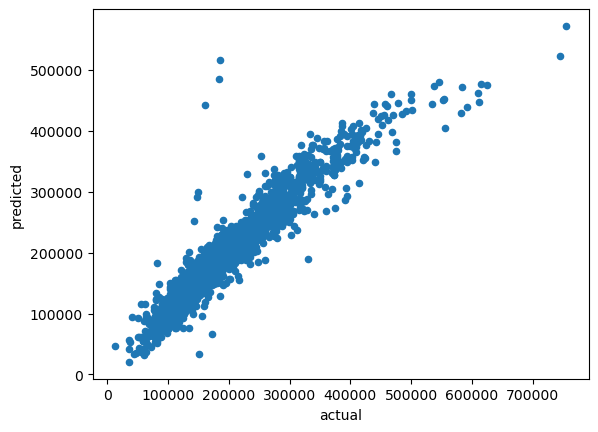

In [52]:
target.plot.scatter(x = "actual", y = "predicted")

## Practice Activity

## Loans Data

The loans data set represents thousands of loans made through the Lending Club platform, which is a platform that allows individuals to lend to other individuals. Of course, not all loans are created equal. Someone who is a essentially a sure bet to pay back a loan will have an easier time getting a loan with a low interest rate than someone who appears to be riskier. And for people who are very risky? They may not even get a loan offer, or they may not have accepted the loan offer due to a high interest rate. It is important to keep that last part in mind, since this dataset only represents loans actually made, i.e. do not mistake this data for loan applications!

[Some information about the data set is here](https://openintrostat.github.io/openintro/reference/loans_full_schema.html). There are also some related exercises in this [OpenIntro textbook](https://openintro-ims.netlify.app/inf-model-mlr.html).

**Our goal will be to develop a regression model for predicting `interest_rate`.**

We will have a competition to see who can come up with the model with the smallest test RMSE. Fit several models and try to find the smallest test RMSE. When you think you have a good one, share your model and its test RMSE. Then see what other people have done; can you do even better?

**Previously you considered selected subsets of features. Now you should try, Ridge, LASSO, and elastic net.**

You should use `GridSearchCV` to tune at least one parameter.

Note: you should do some exploration of the data first before you start fitting models.

In [53]:
df = pd.read_csv("loans_full_schema.csv")

df.head()

,Unnamed: 0,emp_title,emp_length,state,homeownership,annual_income,verified_income,debt_to_income,annual_income_joint,verification_income_joint,...,sub_grade,issue_month,loan_status,initial_listing_status,disbursement_method,balance,paid_total,paid_principal,paid_interest,paid_late_fees
0,1,global config engineer,3.0,NJ,MORTGAGE,90000.0,Verified,18.01,NaN,NaN,...,C3,Mar-2018,Current,whole,Cash,27015.86,1999.33,984.14,1015.19,0.0
1,2,warehouse office clerk,10.0,HI,RENT,40000.0,Not Verified,5.04,NaN,NaN,...,C1,Feb-2018,Current,whole,Cash,4651.37,499.12,348.63,150.49,0.0
2,3,assembly,3.0,WI,RENT,40000.0,Source Verified,21.15,NaN,NaN,...,D1,Feb-2018,Current,fractional,Cash,1824.63,281.80,175.37,106.43,0.0
3,4,customer service,1.0,PA,RENT,30000.0,Not Verified,10.16,NaN,NaN,...,A3,Jan-2018,Current,whole,Cash,18853.26,3312.89,2746.74,566.15,0.0
4,5,security supervisor,10.0,CA,RENT,35000.0,Verified,57.96,57000.0,Verified,...,C3,Mar-2018,Current,whole,Cash,21430.15,2324.65,1569.85,754.80,0.0


In [54]:
# Explore the response, missing values, and how interest rates vary by grade.
display(df["interest_rate"].describe())
display(df.isna().sum().sort_values(ascending=False).head(10))
display(df.groupby("grade")["interest_rate"].mean())

count    10000.000000
mean        12.427524
std          5.001105
min          5.310000
25%          9.430000
50%         11.980000
75%         15.050000
max         30.940000
Name: interest_rate, dtype: float64

verification_income_joint           8545
annual_income_joint                 8505
debt_to_income_joint                8505
months_since_90d_late               7715
months_since_last_delinq            5658
months_since_last_credit_inquiry    1271
emp_title                            833
emp_length                           817
num_accounts_120d_past_due           318
debt_to_income                        24
dtype: int64

grade
A     6.742631
B    10.524103
C    14.176698
D    19.113451
E    25.103403
F    29.401897
G    30.802500
Name: interest_rate, dtype: float64

### Prepare the loan data

As with Ames above, remove columns with many missing values, drop the remaining missing rows, and standardize numerical predictors while dummifying categorical predictors. Repayment fields and `installment` are excluded because they reveal the interest rate or describe events after the loan is made.

In [55]:
good_cols = df.isna().sum() < 100
loans = df.loc[:, good_cols].drop(
    columns=["Unnamed: 0", "installment", "loan_status", "balance",
             "paid_total", "paid_principal", "paid_interest", "paid_late_fees"]
).dropna()

X_loans = loans.drop("interest_rate", axis=1)
y_loans = loans["interest_rate"]

ct_loans = ColumnTransformer([
    ("dummify", OneHotEncoder(sparse_output=False, handle_unknown="ignore"),
     make_column_selector(dtype_include=object)),
    ("standardize", StandardScaler(),
     make_column_selector(dtype_include=np.number))
]).set_output(transform="pandas")

print("Loans used:", len(loans))
print("Predictors used:", X_loans.shape[1])

Loans used: 9976
Predictors used: 38


### Ridge regression

In [56]:
ridge_loans = Pipeline([
    ("preprocessing", ct_loans),
    ("ridge_regression", Ridge(solver="lsqr"))
])

ridge_grid = GridSearchCV(
    ridge_loans,
    {"ridge_regression__alpha": [0.001, 0.01, 0.1, 1, 10]},
    cv=5, scoring="neg_mean_squared_error"
)
ridge_grid.fit(X_loans, y_loans)
print("Best alpha:", ridge_grid.best_params_)
print("CV RMSE:", np.sqrt(-ridge_grid.best_score_))

Best alpha: {'ridge_regression__alpha': 0.01}
CV RMSE: 0.21116405938337207


### LASSO regression

In [57]:
lasso_loans = Pipeline([
    ("preprocessing", ct_loans),
    ("lasso_regression", Lasso(max_iter=20000, tol=0.001))
])

lasso_grid = GridSearchCV(
    lasso_loans,
    {"lasso_regression__alpha": [0.0001, 0.001, 0.01, 0.1, 1]},
    cv=5, scoring="neg_mean_squared_error"
)
lasso_grid.fit(X_loans, y_loans)
print("Best alpha:", lasso_grid.best_params_)
print("CV RMSE:", np.sqrt(-lasso_grid.best_score_))

Best alpha: {'lasso_regression__alpha': 0.0001}
CV RMSE: 0.20234107428133388


### Elastic net regression

In [58]:
elastic_loans = Pipeline([
    ("preprocessing", ct_loans),
    ("elastic_net", ElasticNet(max_iter=10000))
])

elastic_grid = GridSearchCV(
    elastic_loans,
    {"elastic_net__alpha": [0.0001, 0.001, 0.01, 0.1],
     "elastic_net__l1_ratio": [0.25, 0.5, 0.75]},
    cv=5, scoring="neg_mean_squared_error"
)
elastic_grid.fit(X_loans, y_loans)
print("Best parameters:", elastic_grid.best_params_)
print("CV RMSE:", np.sqrt(-elastic_grid.best_score_))

Best parameters: {'elastic_net__alpha': 0.0001, 'elastic_net__l1_ratio': 0.75}
CV RMSE: 0.2115037591663669


### Compare the models

In [59]:
loan_results = pd.Series({
    "Ridge": np.sqrt(-ridge_grid.best_score_),
    "LASSO": np.sqrt(-lasso_grid.best_score_),
    "Elastic net": np.sqrt(-elastic_grid.best_score_)
}, name="CV RMSE (percentage points)")

display(loan_results.sort_values())
print("Best model:", loan_results.idxmin())
print("Lowest estimated test RMSE:", round(loan_results.min(), 3), "percentage points")
print("LASSO coefficients set to zero:",
      (lasso_grid.best_estimator_.named_steps["lasso_regression"].coef_ == 0).sum())

LASSO          0.202341
Ridge          0.211164
Elastic net    0.211504
Name: CV RMSE (percentage points), dtype: float64

Best model: LASSO
Lowest estimated test RMSE: 0.202 percentage points
LASSO coefficients set to zero: 47


**Practice activity result.** LASSO has the smallest five-fold cross-validated RMSE: **0.202 percentage points** at `alpha=0.0001`. Ridge gives **0.211** at `alpha=0.01`, and elastic net gives **0.212** at `alpha=0.0001` and `l1_ratio=0.75`. The selected LASSO model sets 47 coefficients to zero. These RMSE values estimate test error for loans like the accepted loans in this dataset.